# Task 3: Customer Segmentation

## Project: Customer Churn Analysis and Prediction

### Objective
Segment customers based on their tenure, monthly charges, and contract types to understand customer behavior and identify groups with higher churn rates.

### Segmentation Areas
- Customer tenure groups
- Monthly charges groups
- Contract types
- Churn rate across different customer segments

Churn by Tenure Group:
              TotalCustomers  ChurnRate
TenureGroup                            
0-12 months             2186      47.44
13-24 months            1024      28.71
25-48 months            1594      20.39
49-72 months            2239       9.51

Churn by Monthly Charges Group:
                TotalCustomers  ChurnRate
ChargesGroup                             
Low Charges               1838      11.64
Medium Charges            1622      23.92
High Charges              3583      35.36

Churn by Contract Type:
                TotalCustomers  ChurnRate
Contract                                 
Month-to-month            3875      42.71
One year                  1473      11.27
Two year                  1695       2.83

Highest-Risk Combined Segments (at least 30 customers):
                                            TotalCustomers  ChurnRate
TenureGroup  ChargesGroup   Contract                                 
0-12 months  High Charges   Month-to-month             856    

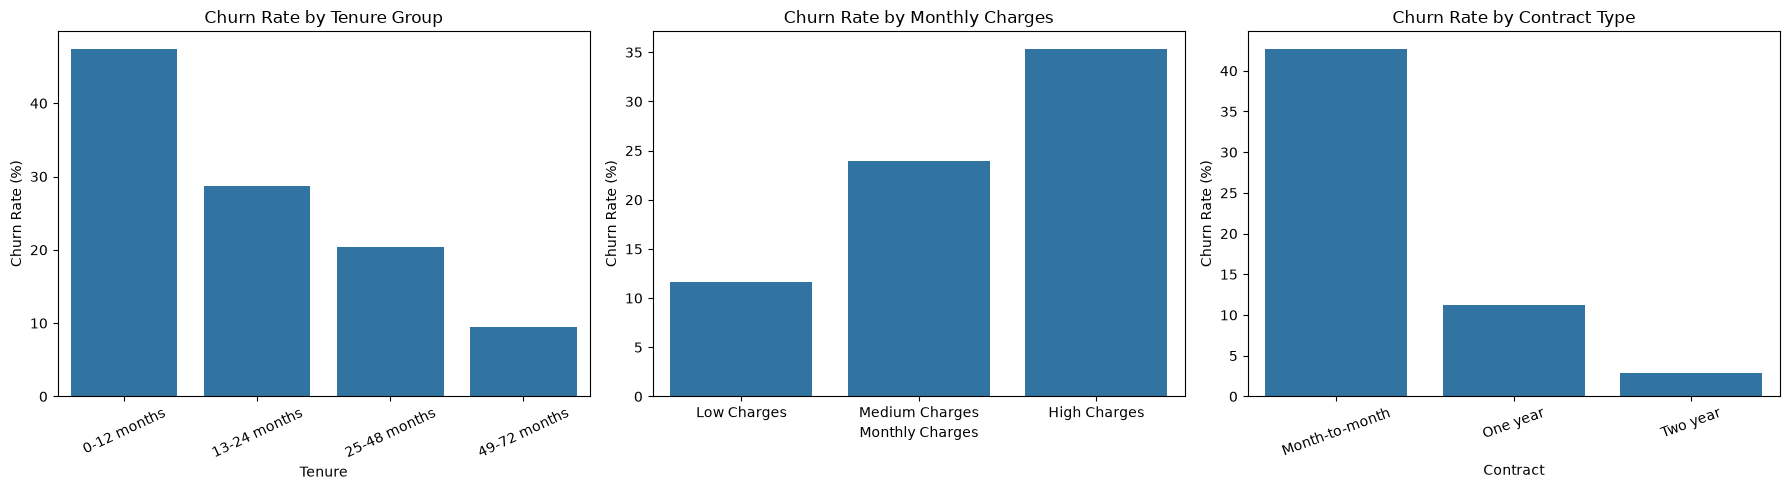

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv(
    r"D:\Saiket_Data_Analysis\data\Telco_Customer_Churn_Cleaned.csv"
)

# 1. Create Tenure Groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
    include_lowest=True
)

# 2. Create Monthly Charges Groups
df["ChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 40, 70, 120],
    labels=["Low Charges", "Medium Charges", "High Charges"],
    include_lowest=True
)

# 3. Analyze Churn by Tenure Group
tenure_segments = (
    df.groupby("TenureGroup", observed=True)
    .agg(
        TotalCustomers=("Churn", "size"),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .round(2)
)

# 4. Analyze Churn by Monthly Charges Group
charges_segments = (
    df.groupby("ChargesGroup", observed=True)
    .agg(
        TotalCustomers=("Churn", "size"),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .round(2)
)

# 5. Analyze Churn by Contract Type
contract_segments = (
    df.groupby("Contract")
    .agg(
        TotalCustomers=("Churn", "size"),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .round(2)
)

# 6. Analyze Combined Customer Segments
combined_segments = (
    df.groupby(
        ["TenureGroup", "ChargesGroup", "Contract"],
        observed=True
    )
    .agg(
        TotalCustomers=("Churn", "size"),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .round(2)
    .sort_values("ChurnRate", ascending=False)
)

# Display Results
print("Churn by Tenure Group:")
print(tenure_segments)

print("\nChurn by Monthly Charges Group:")
print(charges_segments)

print("\nChurn by Contract Type:")
print(contract_segments)

print("\nHighest-Risk Combined Segments (at least 30 customers):")
print(
    combined_segments[combined_segments["TotalCustomers"] >= 30].head(10)
)

# 7. Visualize Customer Segments
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=tenure_segments.reset_index(),
    x="TenureGroup",
    y="ChurnRate",
    ax=axes[0]
)
axes[0].set_title("Churn Rate by Tenure Group")
axes[0].set_xlabel("Tenure")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=charges_segments.reset_index(),
    x="ChargesGroup",
    y="ChurnRate",
    ax=axes[1]
)
axes[1].set_title("Churn Rate by Monthly Charges")
axes[1].set_xlabel("Monthly Charges")
axes[1].set_ylabel("Churn Rate (%)")

sns.barplot(
    data=contract_segments.reset_index(),
    x="Contract",
    y="ChurnRate",
    ax=axes[2]
)
axes[2].set_title("Churn Rate by Contract Type")
axes[2].set_xlabel("Contract")
axes[2].set_ylabel("Churn Rate (%)")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    r"D:\Saiket_Data_Analysis\visualizations\05_customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Key Findings – Customer Segmentation

### 1. Tenure-Based Segmentation
- Customers with 0–12 months of tenure have the highest churn rate (47.44%).
- Churn decreases as customer tenure increases.
- Customers with 49–72 months of tenure have the lowest churn rate (9.51%).

### 2. Monthly Charges Segmentation
- High-charge customers have the highest churn rate (35.36%).
- Medium-charge customers have a churn rate of 23.92%.
- Low-charge customers have the lowest churn rate (11.64%).

### 3. Contract-Based Segmentation
- Month-to-month customers have the highest churn rate (42.71%).
- Two-year contract customers have the lowest churn rate (2.83%).

### 4. Combined Customer Segmentation
- The highest-risk segment consists of customers with:
  - 0–12 months of tenure.
  - High monthly charges.
  - Month-to-month contracts.
- This segment contains 856 customers and has a churn rate of 69.04%.

### Business Recommendations
- Focus retention efforts on new customers during their first year.
- Offer suitable long-term contract incentives.
- Review pricing and service value for high-charge customers.
- Prioritize customers who combine short tenure, high monthly charges, and month-to-month contracts.

**Conclusion:** Customer tenure, monthly charges, and contract type provide useful ways to identify customer segments with different churn risks. Combining these features helps identify high-risk groups more effectively than analyzing each feature separately.

In [2]:
# Save segmentation analysis results

output_dir = r"D:\Saiket_Data_Analysis\data"

tenure_segments.to_csv(
    output_dir + r"\tenure_segmentation.csv"
)

charges_segments.to_csv(
    output_dir + r"\charges_segmentation.csv"
)

contract_segments.to_csv(
    output_dir + r"\contract_segmentation.csv"
)

combined_segments.to_csv(
    output_dir + r"\combined_customer_segments.csv"
)

print("All segmentation results saved successfully!")

All segmentation results saved successfully!
